<a href="https://colab.research.google.com/github/Prajwaln08/SQLSmith/blob/main/02_Spider_Error_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# SQLSmith — Notebook 02: Spider Error Analysis

**Milestone:** A — Baseline Evaluation  
**Model:** Qwen2.5-Coder-1.5B-Instruct  
**Dataset:** Spider 1.0 Development Set  
**Input:** Saved 50-question evaluation from Notebook 01

## Objectives
1. Load saved baseline predictions.
2. Validate result completeness and integrity.
3. Separate execution errors from SQL-result mismatches.
4. Create a structured error taxonomy.
5. Prepare manually reviewable semantic failures.
6. Save evaluation artifacts for Notebook 03.

**Important:** Accuracy reported here is provisional result-match accuracy, not official Spider test-suite accuracy.


## 1. Library Installation

In [24]:
# Install necessary parsing, manipulation, and plotting libraries
%pip install -q pandas numpy matplotlib sqlglot

## 2. Environment Setup and Google Drive Connection

In [25]:
# Mount Google Drive and set up the working directories for the analysis
from google.colab import drive
from pathlib import Path

# Mount drive
drive.mount("/content/drive")

# Define paths
PROJECT_DIR = Path(
    "/content/drive/MyDrive/Prajwal/Projects/SQLSmith"
)
RESULTS_DIR = PROJECT_DIR / "results"
ANALYSIS_DIR = RESULTS_DIR

# Ensure output directories exist
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

INPUT_FILE = RESULTS_DIR / "spider_1_5b_baseline_50.csv"

# Ensure the baseline results file is present
assert INPUT_FILE.exists(), (
    f"Baseline file not found: {INPUT_FILE}"
)

print("Project:", PROJECT_DIR)
print("Results:", RESULTS_DIR)
print("Input file found:", INPUT_FILE.name)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Project: /content/drive/MyDrive/Prajwal/Projects/SQLSmith
Results: /content/drive/MyDrive/Prajwal/Projects/SQLSmith/results
Input file found: spider_1_5b_baseline_50.csv


## 3. Data Load and Baseline Integrity Checks

In [26]:
# Load baseline predictions and validate columns, indices, and correctness formats
import pandas as pd
import numpy as np

# Load the evaluation CSV into a Pandas DataFrame
df = pd.read_csv(INPUT_FILE)

# Define columns required for evaluation
required_columns = [
    "index",
    "db_id",
    "question",
    "gold_sql",
    "predicted_sql",
    "correct",
    "latency_seconds",
    "error"
]

# Ensure all necessary columns exist
missing = [
    col for col in required_columns
    if col not in df.columns
]
assert not missing, f"Missing columns: {missing}"

# Normalize and parse Boolean values safely
def parse_correct(value):
    if isinstance(value, (bool, np.bool_)):
        return bool(value)
    text = str(value).strip().lower()
    if text in ("true", "1"):
        return True
    if text in ("false", "0"):
        return False
    raise ValueError(f"Unexpected correctness value: {value}")

df["correct"] = df["correct"].apply(parse_correct)

# Cast latency to numeric types, handling empty metrics as NaN
df["latency_seconds"] = pd.to_numeric(
    df["latency_seconds"],
    errors="coerce"
)

# Validate unique index constraints and data consistency
assert not df["index"].duplicated().any(), "Duplicate question indices found"
assert not df["db_id"].isna().any(), "Missing database IDs found"

# Display data-load summary metrics
print("Total questions:", len(df))
print("Correct:", int(df["correct"].sum()))
print("Incorrect:", int((~df["correct"]).sum()))
print("Unique databases:", df["db_id"].nunique())

display(df.head())

Total questions: 50
Correct: 24
Incorrect: 26
Unique databases: 2


,index,db_id,question,gold_sql,predicted_sql,correct,latency_seconds,error
0,1,concert_singer,How many singers do we have?,SELECT count(*) FROM singer,SELECT count(*) FROM singer,True,1.379505,NaN
1,2,concert_singer,What is the total number of singers?,SELECT count(*) FROM singer,SELECT count(*) FROM singer,True,1.143007,NaN
2,3,concert_singer,"Show name, country, age for all singers ordere...","SELECT name , country , age FROM singer ORDE...","SELECT Name, Country, Age FROM singer ORDER BY...",True,2.068415,NaN
3,4,concert_singer,"What are the names, countries, and ages for ev...","SELECT name , country , age FROM singer ORDE...","SELECT name, country, age FROM singer ORDER BY...",True,2.294654,NaN
4,5,concert_singer,"What is the average, minimum, and maximum age ...","SELECT avg(age) , min(age) , max(age) FROM s...","SELECT AVG(Age) , MIN(Age) , MAX(Age) FROM s...",True,5.696822,NaN


## 4. Performance Metrics and Baseline Latency Aggregation

In [27]:
# Calculate baseline metrics and summarize performance
accuracy = df["correct"].mean() * 100

# Compute overall latency metrics
mean_latency = df["latency_seconds"].mean()
median_latency = df["latency_seconds"].median()
p95_latency = df["latency_seconds"].quantile(0.95)

# Wrap aggregated metrics in a summary DataFrame
summary_df = pd.DataFrame([{
    "model": "Qwen2.5-Coder-1.5B-Instruct",
    "dataset": "Spider 1.0 dev (first 50)",
    "total_questions": len(df),
    "correct": int(df["correct"].sum()),
    "incorrect": int((~df["correct"]).sum()),
    "provisional_accuracy_pct": round(accuracy, 2),
    "mean_latency_sec": round(mean_latency, 3),
    "median_latency_sec": round(median_latency, 3),
    "p95_latency_sec": round(p95_latency, 3)
}])

display(summary_df)

,model,dataset,total_questions,correct,incorrect,provisional_accuracy_pct,mean_latency_sec,median_latency_sec,p95_latency_sec
0,Qwen2.5-Coder-1.5B-Instruct,Spider 1.0 dev (first 50),50,24,26,48.0,3.629,3.045,9.444


## 5. Filtering and Isolating Execution/Evaluation Failures

In [28]:
# Filter out failed predictions to prepare for taxonomy isolation
failures = df.loc[~df["correct"]].copy()

# Handle and clean null values in core text columns
failures["predicted_sql"] = failures["predicted_sql"].fillna("")
failures["gold_sql"] = failures["gold_sql"].fillna("")
failures["error"] = failures["error"].fillna("")

print("Total failed questions:", len(failures))

# Display structured failure tracking
display(
    failures[
        [
            "index",
            "db_id",
            "question",
            "gold_sql",
            "predicted_sql",
            "error"
        ]
    ]
)

Total failed questions: 26


,index,db_id,question,gold_sql,predicted_sql,error
6,7,concert_singer,Show the name and the release year of the song...,"SELECT song_name , song_release_year FROM sin...","SELECT T2.song_name, T2.song_release_year FROM...",no such column: T2.song_name
7,8,concert_singer,What are the names and release years for all t...,"SELECT song_name , song_release_year FROM sin...","SELECT T2.song_name, T2.song_release_year FROM...",no such column: T2.song_name
8,9,concert_singer,What are all distinct countries where singers ...,SELECT DISTINCT country FROM singer WHERE age ...,SELECT DISTINCT T1.Country FROM singer AS T1 I...,
10,11,concert_singer,Show all countries and the number of singers i...,"SELECT country , count(*) FROM singer GROUP B...","SELECT T1.Country, COUNT(T2.Singer_ID) FROM si...",
11,12,concert_singer,How many singers are from each country?,"SELECT country , count(*) FROM singer GROUP B...","SELECT COUNT(*) , Country FROM singer GROUP B...",
12,13,concert_singer,List all song names by singers above the avera...,SELECT song_name FROM singer WHERE age > (SE...,SELECT T2.song_name FROM singer AS T1 JOIN sin...,no such column: T2.song_name
13,14,concert_singer,What are all the song names by singers who are...,SELECT song_name FROM singer WHERE age > (SE...,SELECT T2.song_name FROM singer AS T1 INNER JO...,no such column: T2.song_name
16,17,concert_singer,What is the maximum capacity and the average o...,"select max(capacity), average from stadium","SELECT max(capacity), avg(capacity) FROM stadium",
18,19,concert_singer,What is the name and capacity for the stadium ...,"SELECT name , capacity FROM stadium ORDER BY ...","SELECT T1.Name, T1.Capacity FROM stadium AS T1...",no such column: T3.Age
19,20,concert_singer,What is the name and capacity for the stadium ...,"SELECT name , capacity FROM stadium ORDER BY ...","SELECT T1.Name, T1.Capacity FROM stadium AS T1...",no such column: Average_number


 ## 6. Categorizing Failure Modes with an Error Taxonomy Rule-Set

In [29]:
# Classify failures based on error messages and missing query logic
def classify_execution_error(row):
    error = str(row["error"]).lower().strip()
    predicted_sql = str(row["predicted_sql"]).strip()

    if not predicted_sql:
        return "Empty generation"
    if not error:
        return "Semantic mismatch - review required"
    if "no such column" in error:
        return "Invalid column"
    if "no such table" in error:
        return "Invalid table"
    if (
        "syntax error" in error
        or "incomplete input" in error
        or "unrecognized token" in error
    ):
        return "SQL syntax error"
    if "interrupted" in error or "timeout" in error:
        return "Execution timeout"
    if "expected a single select" in error:
        return "Query validation rejection"
    if "unsupported" in error:
        return "Unsupported SQL construct"
    if "ambiguous column" in error:
        return "Ambiguous column"

    return "Other execution/evaluation error"

# Apply the error category mapper across row objects
failures["initial_error_category"] = failures.apply(
    classify_execution_error,
    axis=1
)

# Aggregate and count categorical failures
category_counts = (
    failures["initial_error_category"]
    .value_counts()
    .reset_index()
)
category_counts.columns = [
    "error_category",
    "count"
]

display(category_counts)

,error_category,count
0,Invalid column,12
1,Semantic mismatch - review required,9
2,Query validation rejection,5


## 7. Distribution Analysis of Categorized Failure Types

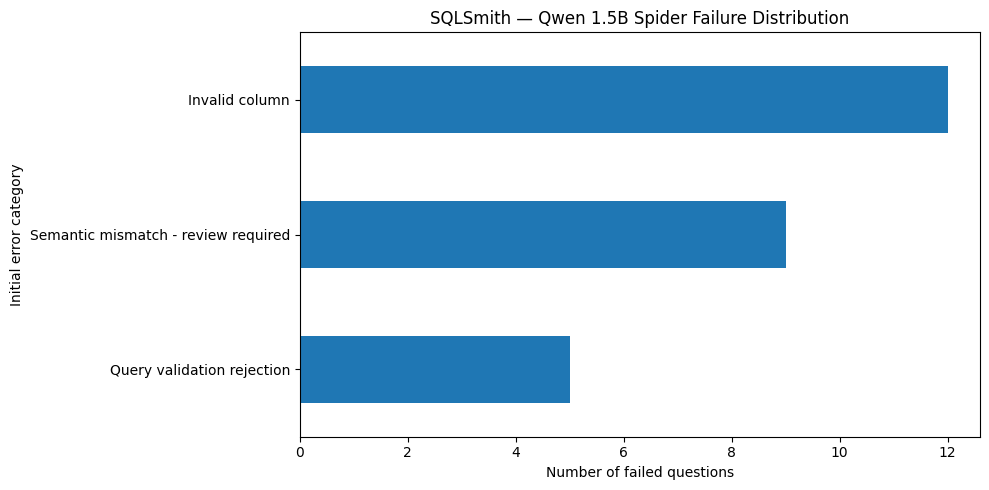

In [30]:
# Visualize error category frequency distributions
import matplotlib.pyplot as plt

# Sort categories for horizontal bar visualization
counts = failures[
    "initial_error_category"
].value_counts().sort_values()

plt.figure(figsize=(10, 5))
counts.plot(kind="barh")

plt.xlabel("Number of failed questions")
plt.ylabel("Initial error category")
plt.title(
    "SQLSmith — Qwen 1.5B Spider Failure Distribution"
)

plt.tight_layout()
plt.show()

## 8. Extracting Semantic Failures for Manual Review and Evaluation

In [31]:
# Filter out valid executions with semantic mismatches for manual review templates
semantic = failures[
    failures["initial_error_category"]
    == "Semantic mismatch - review required"
].copy()

# Prepopulate layout values for user-guided categorization and comments
semantic["manual_error_category"] = ""
semantic["reviewer_notes"] = ""
semantic["review_status"] = "PENDING"
semantic["suggested_root_cause"] = ""

review_columns = [
    "index",
    "db_id",
    "question",
    "gold_sql",
    "predicted_sql",
    "initial_error_category",
    "manual_error_category",
    "suggested_root_cause",
    "reviewer_notes",
    "review_status"
]

review_file = (
    ANALYSIS_DIR /
    "spider_1_5b_error_review_template.csv"
)

# Export template to disk
semantic[review_columns].to_csv(
    review_file,
    index=False
)

print("Semantic review cases:", len(semantic))
print("Saved:", review_file)

display(semantic[review_columns].head(10))

Semantic review cases: 9
Saved: /content/drive/MyDrive/Prajwal/Projects/SQLSmith/results/spider_1_5b_error_review_template.csv


,index,db_id,question,gold_sql,predicted_sql,initial_error_category,manual_error_category,suggested_root_cause,reviewer_notes,review_status
8,9,concert_singer,What are all distinct countries where singers ...,SELECT DISTINCT country FROM singer WHERE age ...,SELECT DISTINCT T1.Country FROM singer AS T1 I...,Semantic mismatch - review required,,,,PENDING
10,11,concert_singer,Show all countries and the number of singers i...,"SELECT country , count(*) FROM singer GROUP B...","SELECT T1.Country, COUNT(T2.Singer_ID) FROM si...",Semantic mismatch - review required,,,,PENDING
11,12,concert_singer,How many singers are from each country?,"SELECT country , count(*) FROM singer GROUP B...","SELECT COUNT(*) , Country FROM singer GROUP B...",Semantic mismatch - review required,,,,PENDING
16,17,concert_singer,What is the maximum capacity and the average o...,"select max(capacity), average from stadium","SELECT max(capacity), avg(capacity) FROM stadium",Semantic mismatch - review required,,,,PENDING
22,23,concert_singer,Show the stadium name and the number of concer...,"SELECT T2.name , count(*) FROM concert AS T1 ...","SELECT T1.Name, COUNT(T2.concert_ID) FROM stad...",Semantic mismatch - review required,,,,PENDING
28,29,concert_singer,Show the stadium names without any concert.,SELECT name FROM stadium WHERE stadium_id NOT ...,SELECT name FROM stadium WHERE stadium_id NOT ...,Semantic mismatch - review required,,,,PENDING
29,30,concert_singer,What are the names of the stadiums without any...,SELECT name FROM stadium WHERE stadium_id NOT ...,SELECT name FROM stadium WHERE stadium_id NOT ...,Semantic mismatch - review required,,,,PENDING
40,41,concert_singer,What is the name and country of origin of ever...,"SELECT name , country FROM singer WHERE song_...","SELECT T1.Name, T1.Country FROM singer AS T1 I...",Semantic mismatch - review required,,,,PENDING
47,48,pets_1,Find the weight of the youngest dog.,SELECT weight FROM pets ORDER BY pet_age LIMIT 1,SELECT T2.weight FROM Has_Pet AS T1 INNER JOIN...,Semantic mismatch - review required,,,,PENDING


## 9. Detailed Step-by-Step Inspectable Review Log

In [32]:
# Iterate over and output all tracked failures in an easily readable terminal format
for _, row in failures.iterrows():
    print("=" * 90)
    print("Question ID:", row["index"])
    print("Database:", row["db_id"])
    print("Question:", row["question"])

    print("\nGOLD SQL:")
    print(row["gold_sql"])

    print("\nPREDICTED SQL:")
    print(row["predicted_sql"])

    print("\nINITIAL CATEGORY:")
    print(row["initial_error_category"])

    if row["error"]:
        print("\nERROR:")
        print(row["error"])

    print()

Question ID: 7
Database: concert_singer
Question: Show the name and the release year of the song by the youngest singer.

GOLD SQL:
SELECT song_name ,  song_release_year FROM singer ORDER BY age LIMIT 1

PREDICTED SQL:
SELECT T2.song_name, T2.song_release_year FROM singer AS T1 INNER JOIN singer_in_concert AS T3 ON T1.singer_id = T3.singer_id INNER JOIN concert AS T4 ON T3.concert_id = T4.concert_id ORDER BY T1.age ASC LIMIT 1

INITIAL CATEGORY:
Invalid column

ERROR:
no such column: T2.song_name

Question ID: 8
Database: concert_singer
Question: What are the names and release years for all the songs of the youngest singer?

GOLD SQL:
SELECT song_name ,  song_release_year FROM singer ORDER BY age LIMIT 1

PREDICTED SQL:
SELECT T2.song_name, T2.song_release_year FROM singer AS T1 INNER JOIN singer_in_concert AS T3 ON T1.singer_id = T3.singer_id INNER JOIN concert AS T4 ON T3.concert_id = T4.concert_id ORDER BY T1.age ASC LIMIT 1

INITIAL CATEGORY:
Invalid column

ERROR:
no such column: 

## 10. Exporting Analysis Artifacts and Executing Health Verifications

In [33]:
# Export evaluation reports, logs, configurations and JSON metadata reports
from datetime import datetime, timezone
import json

# Export details of failures to CSV
error_file = (
    RESULTS_DIR /
    "spider_1_5b_error_analysis.csv"
)
failures.to_csv(error_file, index=False)

# Export failure distribution summary
summary_file = (
    RESULTS_DIR /
    "spider_1_5b_error_summary.csv"
)
category_counts.to_csv(summary_file, index=False)

# Construct summary JSON report mapping evaluation characteristics
report = {
    "experiment": "spider_1_5b_error_analysis",
    "model": "Qwen2.5-Coder-1.5B-Instruct",
    "dataset": "Spider 1.0 development set",
    "sample_size": int(len(df)),
    "correct": int(df["correct"].sum()),
    "incorrect": int((~df["correct"]).sum()),
    "provisional_accuracy_pct": round(accuracy, 2),
    "mean_latency_seconds": round(float(mean_latency), 4),
    "median_latency_seconds": round(float(median_latency), 4),
    "p95_latency_seconds": round(float(p95_latency), 4),
    "semantic_cases_pending_review": int(len(semantic)),
    "initial_error_categories": {
        str(key): int(value)
        for key, value in failures[
            "initial_error_category"
        ].value_counts().items()
    },
    "created_at_utc": datetime.now(
        timezone.utc
    ).isoformat(),
    "evaluation_status": "provisional",
    "official_spider_scoring": False
}

json_file = (
    RESULTS_DIR /
    "spider_1_5b_analysis_summary.json"
)

with open(json_file, "w") as f:
    json.dump(report, f, indent=2)

print("Saved files:")
print(error_file)
print(summary_file)
print(review_file)
print(json_file)

Saved files:
/content/drive/MyDrive/Prajwal/Projects/SQLSmith/results/spider_1_5b_error_analysis.csv
/content/drive/MyDrive/Prajwal/Projects/SQLSmith/results/spider_1_5b_error_summary.csv
/content/drive/MyDrive/Prajwal/Projects/SQLSmith/results/spider_1_5b_error_review_template.csv
/content/drive/MyDrive/Prajwal/Projects/SQLSmith/results/spider_1_5b_analysis_summary.json


In [34]:
# Execute final schema validations on output analysis artifacts
required_outputs = [
    "spider_1_5b_error_analysis.csv",
    "spider_1_5b_error_review_template.csv",
    "spider_1_5b_error_summary.csv",
    "spider_1_5b_analysis_summary.json"
]

# Assert absolute paths of exports exist correctly on drive mount
for filename in required_outputs:
    filepath = RESULTS_DIR / filename
    assert filepath.exists(), (
        f"Missing output: {filename}"
    )
    print("PASS:", filename)

# Double-check total metrics math match sum logic rules
assert len(failures) == int(
    (~df["correct"]).sum()
)
assert category_counts["count"].sum() == len(failures)

print("\nNotebook 02 initial analysis completed.")
print("Manual semantic review remains pending.")

PASS: spider_1_5b_error_analysis.csv
PASS: spider_1_5b_error_review_template.csv
PASS: spider_1_5b_error_summary.csv
PASS: spider_1_5b_analysis_summary.json

Notebook 02 initial analysis completed.
Manual semantic review remains pending.


## 11. Error Analysis.

— ## Section 11: Locating Baseline Error CSV and Initial Filter

In [35]:
import pandas as pd
from pathlib import Path

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Prajwal/Projects/SQLSmith"
)

RESULTS_DIR = PROJECT_DIR / "results"

error_file = (
    RESULTS_DIR / "spider_1_5b_error_analysis.csv"
)

assert error_file.exists(), "Error analysis CSV not found"

failures = pd.read_csv(error_file)

target_categories = [
    "Invalid column",
    "Query validation rejection"
]

investigation_df = failures[
    failures["initial_error_category"].isin(
        target_categories
    )
].copy()

investigation_df["predicted_sql"] = (
    investigation_df["predicted_sql"].fillna("")
)

investigation_df["error"] = (
    investigation_df["error"].fillna("")
)

print("Total cases:", len(investigation_df))

print(
    investigation_df[
        "initial_error_category"
    ].value_counts()
)

display(
    investigation_df[
        [
            "index",
            "db_id",
            "question",
            "initial_error_category",
            "error"
        ]
    ]
)

Total cases: 17
initial_error_category
Invalid column                12
Query validation rejection     5
Name: count, dtype: int64


,index,db_id,question,initial_error_category,error
0,7,concert_singer,Show the name and the release year of the song...,Invalid column,no such column: T2.song_name
1,8,concert_singer,What are the names and release years for all t...,Invalid column,no such column: T2.song_name
5,13,concert_singer,List all song names by singers above the avera...,Invalid column,no such column: T2.song_name
6,14,concert_singer,What are all the song names by singers who are...,Invalid column,no such column: T2.song_name
8,19,concert_singer,What is the name and capacity for the stadium ...,Invalid column,no such column: T3.Age
9,20,concert_singer,What is the name and capacity for the stadium ...,Invalid column,no such column: Average_number
13,31,concert_singer,Show countries where a singer above age 40 and...,Query validation rejection,Expected a single SELECT statement
14,32,concert_singer,Show names for all stadiums except for stadium...,Query validation rejection,Expected a single SELECT statement
15,33,concert_singer,What are the names of all stadiums that did no...,Query validation rejection,Expected a single SELECT statement
16,35,concert_singer,"What are the names , themes , and number of si...",Invalid column,no such column: T2.theme


## 12. Installing Helper Tools for Query Parsing

In [36]:
%pip install -q huggingface_hub sqlglot

## 13. Downloading Public Spider Databases and Setting Directory Map

In [37]:
from pathlib import Path
from huggingface_hub import hf_hub_download
import zipfile
import hashlib

candidates = [
    Path("/content/sqlsmith_data/spider_data/database"),
    Path("/content/sqlsmith_data/database"),
    PROJECT_DIR / "data" / "spider_data" / "database",
    PROJECT_DIR / "data" / "database"
]

db_dir = next(
    (
        p for p in candidates
        if p.exists() and any(p.rglob("*.sqlite"))
    ),
    None
)

if db_dir is None:
    print("Local Spider databases not found.")
    print("Downloading public benchmark databases...")

    archive = hf_hub_download(
        repo_id="HAL-9001/spider-databases",
        repo_type="dataset",
        filename="spider_data.zip"
    )

    expected_hash = (
        "00636695dabed6b5f4b8328a16b13e069a2f16591d5efcce57660669c85b121b"
    )

    with open(archive, "rb") as f:
        actual_hash = hashlib.file_digest(
            f, "sha256"
        ).hexdigest()

    assert actual_hash == expected_hash, (
        "Dataset archive checksum mismatch"
    )

    extract_dir = Path("/content/sqlsmith_data")
    extract_dir.mkdir(parents=True, exist_ok=True)

    with zipfile.ZipFile(archive) as z:
        # Validate archive paths before extraction.
        for member in z.infolist():
            destination = (
                extract_dir / member.filename
            ).resolve()

            assert destination.is_relative_to(
                extract_dir.resolve()
            ), "Unsafe ZIP path"

        z.extractall(extract_dir)

    db_dir = (
        extract_dir / "spider_data" / "database"
    )

assert db_dir.exists(), (
    "Spider database directory not found"
)

print("Database directory:", db_dir)

db_ids = investigation_df["db_id"].unique()

for db_id in db_ids:
    database_path = db_dir / db_id / f"{db_id}.sqlite"

    print(
        db_id,
        "FOUND" if database_path.exists() else "MISSING"
    )

Local Spider databases not found.


spider_data.zip: reconstructing file:   0%|          |  0.00B /  206MB            

spider_data.zip: downloading bytes:           |  0.00B            

Database directory: /content/sqlsmith_data/spider_data/database
concert_singer FOUND
pets_1 FOUND


## 14. Inspecting Actual Schemas from SQLite Database Catalogs

In [38]:
import sqlite3

def quote_identifier(name):
    return '"' + str(name).replace('"', '""') + '"'


def get_actual_schema(db_id):
    database_path = (
        db_dir / db_id / f"{db_id}.sqlite"
    )

    assert database_path.exists(), database_path

    uri = f"{database_path.resolve().as_uri()}?mode=ro"

    connection = sqlite3.connect(
        uri,
        uri=True
    )

    try:
        rows = connection.execute("""
            SELECT name, type
            FROM sqlite_master
            WHERE type IN ('table', 'view')
              AND name NOT LIKE 'sqlite_%'
            ORDER BY name
        """).fetchall()

        schema = {}

        for table_name, object_type in rows:
            pragma_sql = (
                "PRAGMA table_info("
                + quote_identifier(table_name)
                + ")"
            )

            columns = connection.execute(
                pragma_sql
            ).fetchall()

            schema[table_name] = {
                "object_type": object_type,
                "columns": [
                    {
                        "name": col[1],
                        "type": col[2],
                        "primary_key": bool(col[5])
                    }
                    for col in columns
                ]
            }

        return schema

    finally:
        connection.close()


schema_cache = {}

for db_id in investigation_df["db_id"].unique():
    schema_cache[db_id] = get_actual_schema(db_id)

for db_id, schema_info in schema_cache.items():
    print("\n" + "=" * 65)
    print("DATABASE:", db_id)

    for table_name, table_details in schema_info.items():
        columns = [
            c["name"]
            for c in table_details["columns"]
        ]

        print(f"  {table_name}: {columns}")


DATABASE: concert_singer
  concert: ['concert_ID', 'concert_Name', 'Theme', 'Stadium_ID', 'Year']
  singer: ['Singer_ID', 'Name', 'Country', 'Song_Name', 'Song_release_year', 'Age', 'Is_male']
  singer_in_concert: ['concert_ID', 'Singer_ID']
  stadium: ['Stadium_ID', 'Location', 'Name', 'Capacity', 'Highest', 'Lowest', 'Average']

DATABASE: pets_1
  Has_Pet: ['StuID', 'PetID']
  Pets: ['PetID', 'PetType', 'pet_age', 'weight']
  Student: ['StuID', 'LName', 'Fname', 'Age', 'Sex', 'Major', 'Advisor', 'city_code']


## 15. Structural Parsing of SQL via SQLGlot AST

In [39]:
import sqlglot
from sqlglot import exp
import json

def inspect_generated_sql(row):
    db_id = row["db_id"]
    sql = str(row["predicted_sql"])

    actual_schema = schema_cache[db_id]

    actual_tables = {
        table.lower(): table
        for table in actual_schema
    }

    all_columns = set()

    for table_details in actual_schema.values():
        for column in table_details["columns"]:
            all_columns.add(
                column["name"].lower()
            )

    result = {
        "sql_parse_success": False,
        "parsed_root_type": "",
        "referenced_tables": [],
        "referenced_columns": [],
        "missing_tables": [],
        "columns_absent_from_database": [],
        "parser_error": ""
    }

    try:
        statements = sqlglot.parse(
            sql,
            read="sqlite"
        )

        if len(statements) != 1:
            raise ValueError(
                f"Expected one statement, got {len(statements)}"
            )

        tree = statements[0]

        if tree is None:
            raise ValueError("Empty SQL statement")

        result["sql_parse_success"] = True
        result["parsed_root_type"] = type(tree).__name__

        tables = sorted({
            t.name
            for t in tree.find_all(exp.Table)
        })

        columns = sorted({
            c.name
            for c in tree.find_all(exp.Column)
        })

        result["referenced_tables"] = tables
        result["referenced_columns"] = columns

        result["missing_tables"] = [
            t for t in tables
            if t.lower() not in actual_tables
        ]

        # These are candidate column issues, not confirmed
        # hallucinations: aliases and derived tables can
        # introduce column names not present in base tables.
        aliases = {
            alias.alias.lower()
            for alias in tree.find_all(exp.Alias)
            if alias.alias
        }

        result["columns_absent_from_database"] = [
            c for c in columns
            if c.lower() not in all_columns
            and c.lower() not in aliases
        ]

    except Exception as e:
        result["parser_error"] = str(e)

    return result


invalid_columns = investigation_df[
    investigation_df["initial_error_category"]
    == "Invalid column"
].copy()

column_inspections = []

for _, row in invalid_columns.iterrows():

    inspection = inspect_generated_sql(row)

    column_inspections.append({
        "index": row["index"],
        "db_id": row["db_id"],
        "question": row["question"],
        "predicted_sql": row["predicted_sql"],
        "original_error": row["error"],
        **inspection
    })

column_review_df = pd.DataFrame(
    column_inspections
)

display(
    column_review_df[
        [
            "index",
            "db_id",
            "sql_parse_success",
            "missing_tables",
            "columns_absent_from_database",
            "original_error"
        ]
    ]
)

,index,db_id,sql_parse_success,missing_tables,columns_absent_from_database,original_error
0,7,concert_singer,True,[],[],no such column: T2.song_name
1,8,concert_singer,True,[],[],no such column: T2.song_name
2,13,concert_singer,True,[],[],no such column: T2.song_name
3,14,concert_singer,True,[],[],no such column: T2.song_name
4,19,concert_singer,True,[],[],no such column: T3.Age
5,20,concert_singer,True,[],[Average_number],no such column: Average_number
6,35,concert_singer,True,[],[],no such column: T2.theme
7,38,concert_singer,True,[],[],no such column: T3.Name
8,39,concert_singer,True,[],[],no such column: T3.Name
9,40,concert_singer,True,[],[],no such column: T2.Country


## 16. Processing Validation Rejections

In [40]:
validation_cases = investigation_df[
    investigation_df["initial_error_category"]
    == "Query validation rejection"
].copy()

validation_inspections = []

for _, row in validation_cases.iterrows():

    inspection = inspect_generated_sql(row)

    sql = str(row["predicted_sql"])

    parsed_root = inspection["parsed_root_type"]

    is_select_root = (
        parsed_root == "Select"
    )

    validation_inspections.append({
        "index": row["index"],
        "db_id": row["db_id"],
        "question": row["question"],
        "predicted_sql": sql,
        "original_error": row["error"],
        "sql_parse_success": inspection[
            "sql_parse_success"
        ],
        "parsed_root_type": parsed_root,
        "accepted_by_original_root_check": is_select_root,
        "parser_error": inspection["parser_error"],
        "review_status": "PENDING"
    })

validation_review_df = pd.DataFrame(
    validation_inspections
)

display(
    validation_review_df[
        [
            "index",
            "db_id",
            "sql_parse_success",
            "parsed_root_type",
            "accepted_by_original_root_check",
            "original_error"
        ]
    ]
)

,index,db_id,sql_parse_success,parsed_root_type,accepted_by_original_root_check,original_error
0,31,concert_singer,True,Intersect,False,Expected a single SELECT statement
1,32,concert_singer,True,Select,True,Expected a single SELECT statement
2,33,concert_singer,True,Select,True,Expected a single SELECT statement
3,42,concert_singer,True,Select,True,Expected a single SELECT statement
4,43,concert_singer,True,Select,True,Expected a single SELECT statement


## 17. Comprehensive Summary of Failures with Schema Context

In [41]:
for _, row in investigation_df.iterrows():

    db_id = row["db_id"]
    sql = str(row["predicted_sql"])

    inspection = inspect_generated_sql(row)

    print("\n" + "=" * 90)
    print("QUESTION ID:", row["index"])
    print("DATABASE:", db_id)
    print("CATEGORY:", row["initial_error_category"])

    print("\nQUESTION:")
    print(row["question"])

    print("\nGOLD SQL:")
    print(row["gold_sql"])

    print("\nGENERATED SQL:")
    print(sql)

    print("\nORIGINAL ERROR:")
    print(row["error"])

    print("\nSQL PARSER RESULT:")
    print(
        "Parse successful:",
        inspection["sql_parse_success"]
    )
    print(
        "Root type:",
        inspection["parsed_root_type"]
    )

    print("\nSCHEMA EVIDENCE:")
    print(
        "Referenced tables:",
        inspection["referenced_tables"]
    )
    print(
        "Missing tables:",
        inspection["missing_tables"]
    )
    print(
        "Potential missing columns:",
        inspection["columns_absent_from_database"]
    )

    print("\nACTUAL SQLITE TABLES:")
    for table_name, details in schema_cache[db_id].items():
        col_names = [
            col["name"]
            for col in details["columns"]
        ]
        print(f"{table_name}: {', '.join(col_names)}")


QUESTION ID: 7
DATABASE: concert_singer
CATEGORY: Invalid column

QUESTION:
Show the name and the release year of the song by the youngest singer.

GOLD SQL:
SELECT song_name ,  song_release_year FROM singer ORDER BY age LIMIT 1

GENERATED SQL:
SELECT T2.song_name, T2.song_release_year FROM singer AS T1 INNER JOIN singer_in_concert AS T3 ON T1.singer_id = T3.singer_id INNER JOIN concert AS T4 ON T3.concert_id = T4.concert_id ORDER BY T1.age ASC LIMIT 1

ORIGINAL ERROR:
no such column: T2.song_name

SQL PARSER RESULT:
Parse successful: True
Root type: Select

SCHEMA EVIDENCE:
Referenced tables: ['concert', 'singer', 'singer_in_concert']
Missing tables: []
Potential missing columns: []

ACTUAL SQLITE TABLES:
concert: concert_ID, concert_Name, Theme, Stadium_ID, Year
singer: Singer_ID, Name, Country, Song_Name, Song_release_year, Age, Is_male
singer_in_concert: concert_ID, Singer_ID
stadium: Stadium_ID, Location, Name, Capacity, Highest, Lowest, Average

QUESTION ID: 8
DATABASE: concert_

 ## 18. Generating the Initial Deep Review Template

In [42]:
import json

def to_json_text(value):
    return json.dumps(value, ensure_ascii=False)

review_rows = []

for _, row in investigation_df.iterrows():

    inspection = inspect_generated_sql(row)

    review_rows.append({
        "index": row["index"],
        "db_id": row["db_id"],
        "question": row["question"],
        "original_category": row[
            "initial_error_category"
        ],
        "original_error": row["error"],
        "gold_sql": row["gold_sql"],
        "predicted_sql": row["predicted_sql"],
        "sql_parse_success": inspection[
            "sql_parse_success"
        ],
        "parsed_root_type": inspection[
            "parsed_root_type"
        ],
        "missing_tables": to_json_text(
            inspection["missing_tables"]
        ),
        "potential_missing_columns": to_json_text(
            inspection["columns_absent_from_database"]
        ),
        "parser_error": inspection["parser_error"],
        "confirmed_root_cause": "",
        "model_or_evaluator_issue": "",
        "reviewer_notes": "",
        "review_status": "PENDING"
    })

deep_review_df = pd.DataFrame(review_rows)

review_path = (
    RESULTS_DIR /
    "spider_1_5b_deep_error_review.csv"
)

deep_review_df.to_csv(
    review_path,
    index=False
)

print("Review worksheet saved:")
print(review_path)

print("\nRows:", len(deep_review_df))

display(deep_review_df.head())

Review worksheet saved:
/content/drive/MyDrive/Prajwal/Projects/SQLSmith/results/spider_1_5b_deep_error_review.csv

Rows: 17


,index,db_id,question,original_category,original_error,gold_sql,predicted_sql,sql_parse_success,parsed_root_type,missing_tables,potential_missing_columns,parser_error,confirmed_root_cause,model_or_evaluator_issue,reviewer_notes,review_status
0,7,concert_singer,Show the name and the release year of the song...,Invalid column,no such column: T2.song_name,"SELECT song_name , song_release_year FROM sin...","SELECT T2.song_name, T2.song_release_year FROM...",True,Select,[],[],,,,,PENDING
1,8,concert_singer,What are the names and release years for all t...,Invalid column,no such column: T2.song_name,"SELECT song_name , song_release_year FROM sin...","SELECT T2.song_name, T2.song_release_year FROM...",True,Select,[],[],,,,,PENDING
2,13,concert_singer,List all song names by singers above the avera...,Invalid column,no such column: T2.song_name,SELECT song_name FROM singer WHERE age > (SE...,SELECT T2.song_name FROM singer AS T1 JOIN sin...,True,Select,[],[],,,,,PENDING
3,14,concert_singer,What are all the song names by singers who are...,Invalid column,no such column: T2.song_name,SELECT song_name FROM singer WHERE age > (SE...,SELECT T2.song_name FROM singer AS T1 INNER JO...,True,Select,[],[],,,,,PENDING
4,19,concert_singer,What is the name and capacity for the stadium ...,Invalid column,no such column: T3.Age,"SELECT name , capacity FROM stadium ORDER BY ...","SELECT T1.Name, T1.Capacity FROM stadium AS T1...",True,Select,[],[],,,,,PENDING


 ## 19. Saving Baseline Investigation Metadata

In [43]:
from datetime import datetime, timezone
import json

summary = {
    "project": "SQLSmith",
    "notebook": "02_Spider_Error_Analysis",
    "model": "Qwen2.5-Coder-1.5B-Instruct",
    "dataset": "Spider 1.0 dev",
    "investigated_cases": len(deep_review_df),
    "invalid_column_cases": len(invalid_columns),
    "validation_rejection_cases": len(validation_cases),
    "remaining_semantic_cases": int(
        (
            failures["initial_error_category"]
            == "Semantic mismatch - review required"
        ).sum()
    ),
    "sql_parse_success_count": int(
        deep_review_df["sql_parse_success"].sum()
    ),
    "manual_review_status": "PENDING",
    "baseline_accuracy_modified": False,
    "created_at_utc": datetime.now(
        timezone.utc
    ).isoformat()
}

summary_path = (
    RESULTS_DIR /
    "spider_1_5b_deep_investigation_summary.json"
)

with open(summary_path, "w") as f:
    json.dump(summary, f, indent=2)

assert len(deep_review_df) == 17
assert review_path.exists()
assert summary_path.exists()

print(json.dumps(summary, indent=2))

print("\nAll investigation files saved successfully.")

{
  "project": "SQLSmith",
  "notebook": "02_Spider_Error_Analysis",
  "model": "Qwen2.5-Coder-1.5B-Instruct",
  "dataset": "Spider 1.0 dev",
  "investigated_cases": 17,
  "invalid_column_cases": 12,
  "validation_rejection_cases": 5,
  "remaining_semantic_cases": 9,
  "sql_parse_success_count": 17,
  "manual_review_status": "PENDING",
  "baseline_accuracy_modified": false,
  "created_at_utc": "2026-11-22T18:47:14.219932+00:00"
}

All investigation files saved successfully.


 ## 20. Pinpointing Column Ownership and Alias Map Discrepancies

In [44]:
import re
import pandas as pd
import sqlglot
from sqlglot import exp

def inspect_column_ownership(row):
    db_id = row["db_id"]
    sql = str(row["predicted_sql"])

    actual_schema = schema_cache[db_id]

    table_lookup = {
        name.lower(): name
        for name in actual_schema
    }

    statements = sqlglot.parse(sql, read="sqlite")
    findings = []

    if len(statements) != 1 or statements[0] is None:
        return [{
            "index": row["index"],
            "issue": "Requires statement-level review",
            "column": "",
            "alias": "",
            "resolved_table": ""
        }]

    tree = statements[0]

    # Collect table aliases and their actual table names.
    alias_map = {}

    for table in tree.find_all(exp.Table):
        alias_map[table.alias_or_name.lower()] = table.name

    # Resolve qualified column references.
    for column in tree.find_all(exp.Column):
        alias = (column.table or "").lower()
        column_name = column.name

        if not alias:
            continue

        real_table = alias_map.get(alias)

        if real_table is None:
            issue = "Unknown or derived table alias"
            resolved_table = ""

        elif real_table.lower() not in table_lookup:
            issue = "Table not found in physical schema"
            resolved_table = real_table

        else:
            resolved_table = table_lookup[real_table.lower()]

            valid_columns = {
                c["name"].lower()
                for c in actual_schema[
                    resolved_table
                ]["columns"]
            }

            if column_name.lower() in valid_columns:
                issue = "Column exists in referenced table"
            else:
                issue = "Column missing from referenced table"

        findings.append({
            "index": row["index"],
            "db_id": db_id,
            "alias": alias,
            "column": column_name,
            "resolved_table": resolved_table,
            "issue": issue
        })

    return findings


ownership_results = []

for _, row in invalid_columns.iterrows():
    ownership_results.extend(
        inspect_column_ownership(row)
    )

ownership_df = pd.DataFrame(ownership_results)

display(
    ownership_df[
        [
            "index",
            "alias",
            "column",
            "resolved_table",
            "issue"
        ]
    ]
)

print("\nIssue counts:")
print(ownership_df["issue"].value_counts())

,index,alias,column,resolved_table,issue
0,7,t2,song_name,,Unknown or derived table alias
1,7,t2,song_release_year,,Unknown or derived table alias
2,7,t1,singer_id,singer,Column exists in referenced table
3,7,t3,singer_id,singer_in_concert,Column exists in referenced table
4,7,t3,concert_id,singer_in_concert,Column exists in referenced table
...,...,...,...,...,...
66,50,t2,pet_type,Has_Pet,Column missing from referenced table
67,50,t1,weight,Pets,Column exists in referenced table
68,50,t2,pettype,Has_Pet,Column missing from referenced table
69,50,t1,petid,Pets,Column exists in referenced table



Issue counts:
issue
Column exists in referenced table       54
Column missing from referenced table    10
Unknown or derived table alias           7
Name: count, dtype: int64


 ## 21. In-depth Diagnosis of Parser Rejections

In [45]:
import sqlglot
from sqlglot import exp
import pandas as pd

validation_diagnostics = []

for _, row in validation_cases.iterrows():

    sql = str(row["predicted_sql"])

    try:
        statements = sqlglot.parse(
            sql,
            read="sqlite"
        )

        nonempty = [
            stmt for stmt in statements
            if stmt is not None
        ]

        count = len(nonempty)

        root_types = [
            type(stmt).__name__
            for stmt in nonempty
        ]

        original_check_passes = (
            len(statements) == 1
            and isinstance(statements[0], exp.Select)
        )

        if count != 1:
            reason = "Multiple or empty SQL statements"
        elif not isinstance(nonempty[0], exp.Select):
            reason = "Non-SELECT root expression"
        elif not original_check_passes:
            reason = "Original statement-count check failed"
        else:
            reason = "Needs original-validator investigation"

    except Exception as e:
        count = 0
        root_types = []
        original_check_passes = False
        reason = f"Parser exception: {e}"

    validation_diagnostics.append({
        "index": row["index"],
        "db_id": row["db_id"],
        "statement_count": count,
        "root_types": str(root_types),
        "passes_original_check_now": original_check_passes,
        "diagnosis": reason,
        "predicted_sql": sql,
        "original_error": row["error"]
    })

validation_diagnostics_df = pd.DataFrame(
    validation_diagnostics
)

display(validation_diagnostics_df)

for _, row in validation_diagnostics_df.iterrows():
    print("\n" + "=" * 75)
    print("Question:", row["index"])
    print("Diagnosis:", row["diagnosis"])
    print("SQL as stored:", repr(row["predicted_sql"]))

,index,db_id,statement_count,root_types,passes_original_check_now,diagnosis,predicted_sql,original_error
0,31,concert_singer,1,['Intersect'],False,Non-SELECT root expression,SELECT DISTINCT T1.Country FROM singer AS T1 I...,Expected a single SELECT statement
1,32,concert_singer,1,['Select'],True,Needs original-validator investigation,SELECT name FROM stadium WHERE stadium_id NOT ...,Expected a single SELECT statement
2,33,concert_singer,1,['Select'],True,Needs original-validator investigation,SELECT T1.Name FROM stadium AS T1 LEFT JOIN co...,Expected a single SELECT statement
3,42,concert_singer,1,['Select'],True,Needs original-validator investigation,"SELECT T1.Name, T1.Location FROM stadium AS T1...",Expected a single SELECT statement
4,43,concert_singer,1,['Select'],True,Needs original-validator investigation,"SELECT T1.Name, T1.Location FROM stadium AS T1...",Expected a single SELECT statement



Question: 31
Diagnosis: Non-SELECT root expression
SQL as stored: 'SELECT DISTINCT T1.Country FROM singer AS T1 INNER JOIN singer_in_concert AS T2 ON T1.Singer_ID = T2.Singer_ID WHERE T1.Age > 40 INTERSECT SELECT DISTINCT T1.Country FROM singer AS T1 INNER JOIN singer_in_concert AS T2 ON T1.Singer_ID = T2.Singer_ID WHERE T1.Age < 30'

Question: 32
Diagnosis: Needs original-validator investigation
SQL as stored: "SELECT name FROM stadium WHERE stadium_id NOT IN (SELECT stadium_id FROM concert WHERE YEAR = '2014')"

Question: 33
Diagnosis: Needs original-validator investigation
SQL as stored: "SELECT T1.Name FROM stadium AS T1 LEFT JOIN concert AS T2 ON T1.Stadium_ID = T2.Stadium_ID WHERE T2.Year != '2014'"

Question: 42
Diagnosis: Needs original-validator investigation
SQL as stored: "SELECT T1.Name, T1.Location FROM stadium AS T1 JOIN concert AS T2 ON T1.Stadium_ID = T2.Stadium_ID WHERE T2.Year IN ('2014', '2015')"

Question: 43
Diagnosis: Needs original-validator investigation
SQL as

 ## 22. Initializing Semantic Mismatch Records

In [46]:
semantic_cases = failures[
    failures["initial_error_category"]
    == "Semantic mismatch - review required"
].copy()

semantic_review_rows = []

for _, row in semantic_cases.iterrows():

    semantic_review_rows.append({
        "index": row["index"],
        "db_id": row["db_id"],
        "question": row["question"],
        "gold_sql": row["gold_sql"],
        "predicted_sql": row["predicted_sql"],
        "initial_category": (
            "Semantic mismatch - review required"
        ),
        "manual_category": "",
        "reviewer_notes": "",
        "review_status": "PENDING"
    })

semantic_review_df = pd.DataFrame(
    semantic_review_rows
)

display(semantic_review_df)

print(
    "Semantic mismatches pending:",
    len(semantic_review_df)
)

,index,db_id,question,gold_sql,predicted_sql,initial_category,manual_category,reviewer_notes,review_status
0,9,concert_singer,What are all distinct countries where singers ...,SELECT DISTINCT country FROM singer WHERE age ...,SELECT DISTINCT T1.Country FROM singer AS T1 I...,Semantic mismatch - review required,,,PENDING
1,11,concert_singer,Show all countries and the number of singers i...,"SELECT country , count(*) FROM singer GROUP B...","SELECT T1.Country, COUNT(T2.Singer_ID) FROM si...",Semantic mismatch - review required,,,PENDING
2,12,concert_singer,How many singers are from each country?,"SELECT country , count(*) FROM singer GROUP B...","SELECT COUNT(*) , Country FROM singer GROUP B...",Semantic mismatch - review required,,,PENDING
3,17,concert_singer,What is the maximum capacity and the average o...,"select max(capacity), average from stadium","SELECT max(capacity), avg(capacity) FROM stadium",Semantic mismatch - review required,,,PENDING
4,23,concert_singer,Show the stadium name and the number of concer...,"SELECT T2.name , count(*) FROM concert AS T1 ...","SELECT T1.Name, COUNT(T2.concert_ID) FROM stad...",Semantic mismatch - review required,,,PENDING
5,29,concert_singer,Show the stadium names without any concert.,SELECT name FROM stadium WHERE stadium_id NOT ...,SELECT name FROM stadium WHERE stadium_id NOT ...,Semantic mismatch - review required,,,PENDING
6,30,concert_singer,What are the names of the stadiums without any...,SELECT name FROM stadium WHERE stadium_id NOT ...,SELECT name FROM stadium WHERE stadium_id NOT ...,Semantic mismatch - review required,,,PENDING
7,41,concert_singer,What is the name and country of origin of ever...,"SELECT name , country FROM singer WHERE song_...","SELECT T1.Name, T1.Country FROM singer AS T1 I...",Semantic mismatch - review required,,,PENDING
8,48,pets_1,Find the weight of the youngest dog.,SELECT weight FROM pets ORDER BY pet_age LIMIT 1,SELECT T2.weight FROM Has_Pet AS T1 INNER JOIN...,Semantic mismatch - review required,,,PENDING


Semantic mismatches pending: 9


 ## 23. Exporting Diagnostics and v2 Summaries

In [47]:
import json
from datetime import datetime, timezone

ownership_path = (
    RESULTS_DIR / "spider_column_ownership_review.csv"
)

validation_path = (
    RESULTS_DIR / "spider_validation_diagnostics.csv"
)

semantic_path = (
    RESULTS_DIR / "spider_semantic_review.csv"
)

ownership_df.to_csv(ownership_path, index=False)
validation_diagnostics_df.to_csv(
    validation_path, index=False
)
semantic_review_df.to_csv(
    semantic_path, index=False
)

investigation_summary = {
    "model": "Qwen2.5-Coder-1.5B-Instruct",
    "dataset": "Spider 1.0 dev",
    "total_questions": 50,
    "provisional_correct": 24,
    "initial_failed": 26,
    "invalid_column_cases": 12,
    "validation_rejection_cases": 5,
    "semantic_mismatch_cases": 9,
    "column_ownership_issue_counts": {
        str(k): int(v)
        for k, v in ownership_df[
            "issue"
        ].value_counts().items()
    },
    "validation_diagnoses": {
        str(k): int(v)
        for k, v in validation_diagnostics_df[
            "diagnosis"
        ].value_counts().items()
    },
    "baseline_predictions_unchanged": True,
    "manual_review_complete": False,
    "updated_at_utc": datetime.now(
        timezone.utc
    ).isoformat()
}

summary_path = (
    RESULTS_DIR / "spider_investigation_v2.json"
)

with open(summary_path, "w") as f:
    json.dump(investigation_summary, f, indent=2)

for path in [
    ownership_path,
    validation_path,
    semantic_path,
    summary_path
]:
    assert path.exists()
    print("SAVED:", path.name)

print("\nInvestigation evidence saved.")

SAVED: spider_column_ownership_review.csv
SAVED: spider_validation_diagnostics.csv
SAVED: spider_semantic_review.csv
SAVED: spider_investigation_v2.json

Investigation evidence saved.


 ## 24. Verifying SQLGlot Recheck Actions

In [48]:

import sqlglot
from sqlglot import exp
import pandas as pd

recheck_rows = []

for _, row in validation_cases.iterrows():
    sql = str(row["predicted_sql"])

    try:
        parsed = sqlglot.parse(sql, read="sqlite")

        original_condition = (
            len(parsed) == 1
            and isinstance(parsed[0], exp.Select)
        )

        root = (
            type(parsed[0]).__name__
            if parsed and parsed[0] is not None
            else "None"
        )

        recheck_rows.append({
            "index": row["index"],
            "db_id": row["db_id"],
            "statement_count": len(parsed),
            "root_type": root,
            "original_condition_passes_now": original_condition,
            "original_error": row["error"],
            "needs_reconciliation": original_condition,
        })

    except Exception as e:
        recheck_rows.append({
            "index": row["index"],
            "db_id": row["db_id"],
            "statement_count": None,
            "root_type": "ParseError",
            "original_condition_passes_now": False,
            "original_error": row["error"],
            "needs_reconciliation": True,
        })

recheck_df = pd.DataFrame(recheck_rows)

display(recheck_df)

print("SQLGlot version:", sqlglot.__version__)
print(
    "Cases requiring reconciliation:",
    int(recheck_df["needs_reconciliation"].sum())
)


,index,db_id,statement_count,root_type,original_condition_passes_now,original_error,needs_reconciliation
0,31,concert_singer,1,Intersect,False,Expected a single SELECT statement,False
1,32,concert_singer,1,Select,True,Expected a single SELECT statement,True
2,33,concert_singer,1,Select,True,Expected a single SELECT statement,True
3,42,concert_singer,1,Select,True,Expected a single SELECT statement,True
4,43,concert_singer,1,Select,True,Expected a single SELECT statement,True


SQLGlot version: 25.20.2
Cases requiring reconciliation: 4


 ## 25. Validating Compilation Plans on Real Databases

In [49]:

import sqlite3
import time
from sqlglot import exp

READ_ONLY_ROOTS = (
    exp.Select,
    exp.Intersect,
    exp.Union,
    exp.Except
)

def check_sqlite_compilation(db_id, sql):
    try:
        statements = sqlglot.parse(sql, read="sqlite")

        if (
            len(statements) != 1
            or not isinstance(statements[0], READ_ONLY_ROOTS)
        ):
            return False, "Unsupported statement structure"

        database_path = (
            db_dir / db_id / f"{db_id}.sqlite"
        ).resolve()

        uri = database_path.as_uri() + "?mode=ro"

        conn = sqlite3.connect(
            uri,
            uri=True,
            timeout=5
        )

        try:
            conn.execute("PRAGMA query_only = ON")

            deadline = time.monotonic() + 5

            conn.set_progress_handler(
                lambda: int(time.monotonic() > deadline),
                1000
            )

            # Compilation/plan inspection, not result retrieval.
            conn.execute(
                "EXPLAIN QUERY PLAN " + sql
            ).fetchall()

            return True, ""

        finally:
            conn.close()

    except Exception as e:
        return False, str(e)


compilation_rows = []

for _, row in investigation_df.iterrows():

    success, error = check_sqlite_compilation(
        row["db_id"],
        row["predicted_sql"]
    )

    compilation_rows.append({
        "index": row["index"],
        "db_id": row["db_id"],
        "initial_category": row["initial_error_category"],
        "sqlite_compiles": success,
        "sqlite_error": error
    })

compilation_df = pd.DataFrame(compilation_rows)

display(compilation_df)

print("\nCompilation summary:")
display(
    compilation_df.groupby(
        ["initial_category", "sqlite_compiles"]
    ).size().reset_index(name="count")
)


,index,db_id,initial_category,sqlite_compiles,sqlite_error
0,7,concert_singer,Invalid column,False,no such column: T2.song_name
1,8,concert_singer,Invalid column,False,no such column: T2.song_name
2,13,concert_singer,Invalid column,False,no such column: T2.song_name
3,14,concert_singer,Invalid column,False,no such column: T2.song_name
4,19,concert_singer,Invalid column,False,no such column: T3.Age
5,20,concert_singer,Invalid column,False,no such column: Average_number
6,31,concert_singer,Query validation rejection,True,
7,32,concert_singer,Query validation rejection,True,
8,33,concert_singer,Query validation rejection,True,
9,35,concert_singer,Invalid column,False,no such column: T2.theme



Compilation summary:


,initial_category,sqlite_compiles,count
0,Invalid column,False,12
1,Query validation rejection,True,5


 ## 26. Building Consolidated Question Case Summaries

In [60]:

column_case_rows = []

for question_id, group in ownership_df.groupby("index"):

    issues = group["issue"].value_counts()

    missing = group[
        group["issue"]
        == "Column missing from referenced table"
    ]

    unresolved = group[
        group["issue"]
        == "Unknown or derived table alias"
    ]

    column_case_rows.append({
        "index": question_id,
        "total_column_references": len(group),
        "missing_from_referenced_table": len(missing),
        "unresolved_alias_references": len(unresolved),
        "missing_column_details": "; ".join(
            missing["alias"].astype(str)
            + "."
            + missing["column"].astype(str)
        ),
        "unresolved_alias_details": "; ".join(
            unresolved["alias"].astype(str)
            + "."
            + unresolved["column"].astype(str)
        ),
        "requires_manual_scope_review": (
            len(unresolved) > 0
        )
    })

column_case_summary = pd.DataFrame(
    column_case_rows
).sort_values("index")

display(column_case_summary)

print(
    "Questions with missing columns on resolved tables:",
    int(
        (
            column_case_summary[
                "missing_from_referenced_table"
            ] > 0
        ).sum()
    )
)

print(
    "Questions with unresolved alias references:",
    int(
        column_case_summary[
            "requires_manual_scope_review"
        ].sum()
    )
)


,index,total_column_references,missing_from_referenced_table,unresolved_alias_references,missing_column_details,unresolved_alias_details,requires_manual_scope_review
0,7,7,0,2,,t2.song_name; t2.song_release_year,True
1,8,7,0,2,,t2.song_name; t2.song_release_year,True
2,13,6,0,1,,t2.song_name,True
3,14,6,0,1,,t2.song_name,True
4,19,8,1,0,t3.Age,,False
5,20,4,0,1,,t2.Stadium_ID,True
6,35,6,2,0,t2.theme; t2.theme,,False
7,38,6,1,0,t3.Name,,False
8,39,6,1,0,t3.Name,,False
9,40,5,2,0,t2.Country; t2.song_name,,False


Questions with missing columns on resolved tables: 7
Questions with unresolved alias references: 5


 ## 27. Storing Diagnostics and Compilation Metadata Reports

In [51]:

import json
from datetime import datetime, timezone

outputs = {
    "spider_validator_recheck.csv": recheck_df,
    "spider_sqlite_compilation_review.csv": compilation_df,
    "spider_column_case_summary.csv": column_case_summary
}

for filename, dataframe in outputs.items():
    path = RESULTS_DIR / filename
    dataframe.to_csv(path, index=False)
    print("SAVED:", path.name)

diagnostic_report = {
    "model": "Qwen2.5-Coder-1.5B-Instruct",
    "original_provisional_accuracy": 0.48,
    "original_correct": 24,
    "original_total": 50,
    "investigated_cases": len(investigation_df),
    "sqlite_compilation_successes": int(
        compilation_df["sqlite_compiles"].sum()
    ),
    "validator_cases_needing_reconciliation": int(
        recheck_df["needs_reconciliation"].sum()
    ),
    "semantic_cases_still_pending": 9,
    "baseline_modified": False,
    "review_status": "Diagnostics saved; manual review pending",
    "created_at_utc": datetime.now(
        timezone.utc
    ).isoformat()
}

report_path = RESULTS_DIR / "spider_diagnostic_report.json"

with open(report_path, "w") as f:
    json.dump(diagnostic_report, f, indent=2)

print("\nDiagnostic report saved.")
print(json.dumps(diagnostic_report, indent=2))


SAVED: spider_validator_recheck.csv
SAVED: spider_sqlite_compilation_review.csv
SAVED: spider_column_case_summary.csv

Diagnostic report saved.
{
  "model": "Qwen2.5-Coder-1.5B-Instruct",
  "original_provisional_accuracy": 0.48,
  "original_correct": 24,
  "original_total": 50,
  "investigated_cases": 17,
  "sqlite_compilation_successes": 5,
  "validator_cases_needing_reconciliation": 4,
  "semantic_cases_still_pending": 9,
  "baseline_modified": false,
  "review_status": "Diagnostics saved; manual review pending",
  "created_at_utc": "2026-11-22T18:56:46.220337+00:00"
}


 ## 28. Executing Live Replay of Queries to Compare Results

In [52]:

import sqlite3
import time
import pandas as pd
import sqlglot
from sqlglot import exp
from collections import Counter

READ_ONLY_ROOTS = (
    exp.Select,
    exp.Intersect,
    exp.Union,
    exp.Except
)

def execute_review_query(db_id, sql, timeout=5):
    statements = sqlglot.parse(sql, read="sqlite")

    if (
        len(statements) != 1
        or not isinstance(statements[0], READ_ONLY_ROOTS)
    ):
        raise ValueError("Unsupported SQL structure")

    db_path = (
        db_dir / db_id / f"{db_id}.sqlite"
    ).resolve()

    uri = db_path.as_uri() + "?mode=ro"

    conn = sqlite3.connect(uri, uri=True, timeout=timeout)

    try:
        conn.execute("PRAGMA query_only = ON")

        deadline = time.monotonic() + timeout
        conn.set_progress_handler(
            lambda: int(time.monotonic() > deadline),
            1000
        )

        return conn.execute(sql).fetchall()

    finally:
        conn.close()


def normalize_review_rows(rows):
    return Counter(
        tuple(
            round(v, 6) if isinstance(v, float) else v
            for v in row
        )
        for row in rows
    )


replay_results = []

for _, row in validation_cases.iterrows():

    try:
        predicted_rows = execute_review_query(
            row["db_id"],
            row["predicted_sql"]
        )

        gold_rows = execute_review_query(
            row["db_id"],
            row["gold_sql"]
        )

        matches = (
            normalize_review_rows(predicted_rows)
            == normalize_review_rows(gold_rows)
        )

        replay_results.append({
            "index": row["index"],
            "db_id": row["db_id"],
            "sqlite_executed": True,
            "provisional_result_match": matches,
            "predicted_row_count": len(predicted_rows),
            "gold_row_count": len(gold_rows),
            "error": ""
        })

    except Exception as e:
        replay_results.append({
            "index": row["index"],
            "db_id": row["db_id"],
            "sqlite_executed": False,
            "provisional_result_match": False,
            "predicted_row_count": None,
            "gold_row_count": None,
            "error": str(e)
        })


replay_df = pd.DataFrame(replay_results)

display(replay_df)

print(
    "Successfully executed:",
    int(replay_df["sqlite_executed"].sum())
)

print(
    "Provisional result matches:",
    int(replay_df["provisional_result_match"].sum())
)


,index,db_id,sqlite_executed,provisional_result_match,predicted_row_count,gold_row_count,error
0,31,concert_singer,True,True,1,1,
1,32,concert_singer,True,True,6,6,
2,33,concert_singer,True,False,3,6,
3,42,concert_singer,True,False,6,1,
4,43,concert_singer,True,False,6,1,


Successfully executed: 5
Provisional result matches: 2


 ## 29. Tracking Performance Accuracy Improvements

In [53]:

original_correct = int(df["correct"].sum())
total_questions = len(df)

additional_matches = int(
    replay_df["provisional_result_match"].sum()
)

comparison_df = pd.DataFrame([
    {
        "metric": "Original provisional result-match",
        "correct": original_correct,
        "total": total_questions,
        "accuracy_pct": round(
            100 * original_correct / total_questions, 2
        )
    },
    {
        "metric": "Diagnostic replay (not official)",
        "correct": original_correct + additional_matches,
        "total": total_questions,
        "accuracy_pct": round(
            100 * (original_correct + additional_matches)
            / total_questions, 2
        )
    }
])

display(comparison_df)

print(
    "Original benchmark files remain unchanged."
)


,metric,correct,total,accuracy_pct
0,Original provisional result-match,24,50,48.0
1,Diagnostic replay (not official),26,50,52.0


Original benchmark files remain unchanged.


 ## 30. Consolidation of Multi-source Review Evidence

In [54]:

import pandas as pd

consolidated = failures.copy()

consolidated = consolidated.merge(
    compilation_df[
        ["index", "sqlite_compiles", "sqlite_error"]
    ],
    on="index",
    how="left",
    validate="one_to_one"
)

consolidated = consolidated.merge(
    replay_df[
        ["index", "provisional_result_match"]
    ],
    on="index",
    how="left",
    validate="one_to_one"
)

consolidated["provisional_result_match"] = (
    consolidated["provisional_result_match"]
    .astype("boolean")
)

consolidated["root_cause"] = ""
consolidated["review_notes"] = ""
consolidated["review_status"] = "PENDING"

assert len(consolidated) == 26
assert consolidated["index"].is_unique

display(
    consolidated[
        [
            "index",
            "db_id",
            "initial_error_category",
            "sqlite_compiles",
            "provisional_result_match",
            "review_status"
        ]
    ]
)


,index,db_id,initial_error_category,sqlite_compiles,provisional_result_match,review_status
0,7,concert_singer,Invalid column,False,<NA>,PENDING
1,8,concert_singer,Invalid column,False,<NA>,PENDING
2,9,concert_singer,Semantic mismatch - review required,NaN,<NA>,PENDING
3,11,concert_singer,Semantic mismatch - review required,NaN,<NA>,PENDING
4,12,concert_singer,Semantic mismatch - review required,NaN,<NA>,PENDING
5,13,concert_singer,Invalid column,False,<NA>,PENDING
6,14,concert_singer,Invalid column,False,<NA>,PENDING
7,17,concert_singer,Semantic mismatch - review required,NaN,<NA>,PENDING
8,19,concert_singer,Invalid column,False,<NA>,PENDING
9,20,concert_singer,Invalid column,False,<NA>,PENDING


 ## 31. Writing Replay Logs and Evaluation Files

In [55]:

import json
from datetime import datetime, timezone

replay_path = (
    RESULTS_DIR /
    "spider_validation_replay.csv"
)

consolidated_path = (
    RESULTS_DIR /
    "spider_consolidated_error_review.csv"
)

replay_df.to_csv(replay_path, index=False)
consolidated.to_csv(consolidated_path, index=False)

summary = {
    "model": "Qwen2.5-Coder-1.5B-Instruct",
    "original_provisional_accuracy": 0.48,
    "original_correct": 24,
    "total_questions": 50,
    "invalid_column_compilation_failures": 12,
    "validation_rejections_replayed": 5,
    "validation_replay_matches": int(
        replay_df["provisional_result_match"].sum()
    ),
    "semantic_mismatches_pending": 9,
    "official_evaluation_complete": False,
    "baseline_unchanged": True,
    "generated_at_utc": datetime.now(
        timezone.utc
    ).isoformat()
}

summary_path = (
    RESULTS_DIR /
    "spider_notebook02_replay_summary.json"
)

with open(summary_path, "w") as f:
    json.dump(summary, f, indent=2)

print("Saved:")
print(replay_path)
print(consolidated_path)
print(summary_path)


Saved:
/content/drive/MyDrive/Prajwal/Projects/SQLSmith/results/spider_validation_replay.csv
/content/drive/MyDrive/Prajwal/Projects/SQLSmith/results/spider_consolidated_error_review.csv
/content/drive/MyDrive/Prajwal/Projects/SQLSmith/results/spider_notebook02_replay_summary.json


 ## 32. Outputting Semantic Failures for Analysis

In [56]:
semantic_cases = failures[
    failures["initial_error_category"]
    == "Semantic mismatch - review required"
].copy()

print("Semantic cases:", len(semantic_cases))

for _, row in semantic_cases.iterrows():
    print("\n" + "=" * 100)
    print("QUESTION ID:", row["index"])
    print("DATABASE:", row["db_id"])
    print("QUESTION:", row["question"])

    print("\nGOLD SQL:")
    print(row["gold_sql"])

    print("\nPREDICTED SQL:")
    print(row["predicted_sql"])

    print("\nORIGINAL ERROR:")
    print(row["error"] if pd.notna(row["error"]) else "None")

Semantic cases: 9

QUESTION ID: 9
DATABASE: concert_singer
QUESTION: What are all distinct countries where singers above age 20 are from?

GOLD SQL:
SELECT DISTINCT country FROM singer WHERE age  >  20

PREDICTED SQL:
SELECT DISTINCT T1.Country FROM singer AS T1 INNER JOIN singer_in_concert AS T2 ON T1.Singer_ID = T2.Singer_ID WHERE T1.Age > 20

ORIGINAL ERROR:
None

QUESTION ID: 11
DATABASE: concert_singer
QUESTION: Show all countries and the number of singers in each country.

GOLD SQL:
SELECT country ,  count(*) FROM singer GROUP BY country

PREDICTED SQL:
SELECT T1.Country, COUNT(T2.Singer_ID) FROM singer AS T1 JOIN singer_in_concert AS T2 ON T1.Singer_ID = T2.Singer_ID GROUP BY T1.Country

ORIGINAL ERROR:
None

QUESTION ID: 12
DATABASE: concert_singer
QUESTION: How many singers are from each country?

GOLD SQL:
SELECT country ,  count(*) FROM singer GROUP BY country

PREDICTED SQL:
SELECT COUNT(*) ,  Country FROM singer GROUP BY Country

ORIGINAL ERROR:
None

QUESTION ID: 17
DATAB

 ## 33. Injecting Hand-curated Classifications for the Semantic Cases

In [57]:

import pandas as pd

manual_classifications = {
    9: (
        "Unnecessary join",
        "Join to singer_in_concert can exclude singers without concerts."
    ),
    11: (
        "Incorrect aggregation due to join",
        "Counts concert associations instead of singers."
    ),
    12: (
        "Column-order mismatch",
        "Same grouping/count logic, output columns reversed."
    ),
    17: (
        "Wrong aggregation interpretation",
        "Uses AVG(capacity) instead of stadium.average."
    ),
    23: (
        "Incorrect join relationship",
        "Uses singer_in_concert instead of joining concert to stadium."
    ),
    29: (
        "Wrong table selection",
        "Subquery uses singer_in_concert instead of concert."
    ),
    30: (
        "Wrong table selection",
        "Same issue as question 29."
    ),
    41: (
        "Wrong semantic grounding",
        "Matches concert theme rather than singer song title."
    ),
    48: (
        "Possible benchmark reference issue",
        "Question specifies dogs, but gold SQL has no dog filter."
    )
}

semantic_review_df = semantic_cases.copy()

semantic_review_df["manual_category"] = (
    semantic_review_df["index"]
    .map(lambda i: manual_classifications[int(i)][0])
)

semantic_review_df["reviewer_notes"] = (
    semantic_review_df["index"]
    .map(lambda i: manual_classifications[int(i)][1])
)

semantic_review_df["review_status"] = (
    semantic_review_df["index"]
    .map(
        lambda i: (
            "NEEDS_REFERENCE_REVIEW"
            if int(i) == 48
            else "CLASSIFIED"
        )
    )
)

assert len(semantic_review_df) == 9

display(
    semantic_review_df[
        [
            "index",
            "manual_category",
            "reviewer_notes",
            "review_status"
        ]
    ]
)


,index,manual_category,reviewer_notes,review_status
2,9,Unnecessary join,Join to singer_in_concert can exclude singers ...,CLASSIFIED
3,11,Incorrect aggregation due to join,Counts concert associations instead of singers.,CLASSIFIED
4,12,Column-order mismatch,"Same grouping/count logic, output columns reve...",CLASSIFIED
7,17,Wrong aggregation interpretation,Uses AVG(capacity) instead of stadium.average.,CLASSIFIED
10,23,Incorrect join relationship,Uses singer_in_concert instead of joining conc...,CLASSIFIED
11,29,Wrong table selection,Subquery uses singer_in_concert instead of con...,CLASSIFIED
12,30,Wrong table selection,Same issue as question 29.,CLASSIFIED
20,41,Wrong semantic grounding,Matches concert theme rather than singer song ...,CLASSIFIED
23,48,Possible benchmark reference issue,"Question specifies dogs, but gold SQL has no d...",NEEDS_REFERENCE_REVIEW


 ## 34. Final Review Synthesis and Output Serialization

In [58]:

from pathlib import Path

RESULTS_DIR = Path(
    "/content/drive/MyDrive/Prajwal/Projects/SQLSmith/results"
)

semantic_path = (
    RESULTS_DIR /
    "spider_1_5b_semantic_review_final.csv"
)

semantic_review_df.to_csv(
    semantic_path,
    index=False
)

consolidated_final = consolidated.copy()

semantic_map = (
    semantic_review_df.set_index("index")[
        ["manual_category", "reviewer_notes", "review_status"]
    ].to_dict("index")
)

for idx, row in consolidated_final.iterrows():
    question_id = int(row["index"])

    if question_id in semantic_map:
        review = semantic_map[question_id]

        consolidated_final.at[
            idx, "root_cause"
        ] = review["manual_category"]

        consolidated_final.at[
            idx, "review_notes"
        ] = review["reviewer_notes"]

        consolidated_final.at[
            idx, "review_status"
        ] = review["review_status"]

    elif row["initial_error_category"] == "Invalid column":
        consolidated_final.at[
            idx, "root_cause"
        ] = "Confirmed SQLite column-resolution failure"

        consolidated_final.at[
            idx, "review_status"
        ] = "DIAGNOSED"

    elif row["initial_error_category"] == "Query validation rejection":
        match = row["provisional_result_match"]

        consolidated_final.at[
            idx, "root_cause"
        ] = (
            "Validator rejection; replay result matches"
            if pd.notna(match) and bool(match)
            else "Validator rejection; replay result mismatch"
        )

        consolidated_final.at[
            idx, "review_status"
        ] = "DIAGNOSED"

final_path = (
    RESULTS_DIR /
    "spider_1_5b_consolidated_review_final.csv"
)

consolidated_final.to_csv(
    final_path,
    index=False
)

print("Saved:", semantic_path.name)
print("Saved:", final_path.name)

print("\nReview status:")
print(consolidated_final["review_status"].value_counts())


Saved: spider_1_5b_semantic_review_final.csv
Saved: spider_1_5b_consolidated_review_final.csv

Review status:
review_status
DIAGNOSED                 17
CLASSIFIED                 8
NEEDS_REFERENCE_REVIEW     1
Name: count, dtype: int64


 ## 35. Generating final diagnostic report

In [59]:

import json
from datetime import datetime, timezone

report = {
    "project": "SQLSmith",
    "milestone": "A",
    "notebook": "02_Spider_Error_Analysis",
    "model": "Qwen2.5-Coder-1.5B-Instruct",
    "dataset": "Spider 1.0 dev, first 50",
    "original_correct": 24,
    "original_provisional_accuracy": 0.48,
    "diagnostic_replay_correct": 26,
    "diagnostic_replay_accuracy": 0.52,
    "initial_failures": 26,
    "confirmed_sqlite_column_failures": 12,
    "validation_rejections": 5,
    "validation_replay_matches": 2,
    "semantic_cases_reviewed": 9,
    "possible_reference_issue_ids": [48],
    "official_spider_evaluation_complete": False,
    "baseline_predictions_modified": False,
    "generated_at_utc": datetime.now(
        timezone.utc
    ).isoformat()
}

report_path = (
    RESULTS_DIR /
    "spider_notebook02_final_report.json"
)

with open(report_path, "w") as f:
    json.dump(report, f, indent=2)

assert semantic_path.exists()
assert final_path.exists()
assert report_path.exists()
assert len(consolidated_final) == 26

print(json.dumps(report, indent=2))

print("\nNotebook 02 diagnostic review saved.")
print("Official evaluation and reference adjudication remain pending.")


{
  "project": "SQLSmith",
  "milestone": "A",
  "notebook": "02_Spider_Error_Analysis",
  "model": "Qwen2.5-Coder-1.5B-Instruct",
  "dataset": "Spider 1.0 dev, first 50",
  "original_correct": 24,
  "original_provisional_accuracy": 0.48,
  "diagnostic_replay_correct": 26,
  "diagnostic_replay_accuracy": 0.52,
  "initial_failures": 26,
  "confirmed_sqlite_column_failures": 12,
  "validation_rejections": 5,
  "validation_replay_matches": 2,
  "semantic_cases_reviewed": 9,
  "possible_reference_issue_ids": [
    48
  ],
  "official_spider_evaluation_complete": false,
  "baseline_predictions_modified": false,
  "generated_at_utc": "2026-11-22T19:01:55.677061+00:00"
}

Notebook 02 diagnostic review saved.
Official evaluation and reference adjudication remain pending.
